In [1]:
if(!require("pacman")) install.packages("pacman")
pacman::p_load(knitr, arrow, gt, ggsci, patchwork, binom, psych, tidyverse)

Loading required package: pacman



# Data

The main analysis keeps one visit per patient. This is the check on that choice: how much of the data it drops, who the dropped visits belong to, and whether any of the numbers move if I keep every visit instead.

In [2]:
# The joined file is 88 columns and I only need a handful, so read those
ed_data <- read_parquet(
  "../MIMICED/ed_join_cc.parquet",
  col_select = c(subject_id, intime, age, gender, race, acuity, nyu, res, acuity_out)
) |>
  # same grouping column the main analysis uses
  mutate(
    combined_group = paste0(nyu, res, acuity_out)
  )

print(paste("N of visits in the file:", nrow(ed_data)))

[1] "N of visits in the file: 424707"


Same two cohort steps as the main analysis. Drop the rows missing acuity, age or race, then take each patient's first visit.

In [3]:
ed_elig <- ed_data |>
  filter(!is.na(acuity) & !is.na(age) & !is.na(race))

ed_first <- ed_elig |>
  arrange(intime) |>
  group_by(subject_id) |>
  slice_head(n = 1) |>
  ungroup()

n_elig  <- nrow(ed_elig)
n_first <- nrow(ed_first)

print(paste("Eligible visits:", n_elig))
print(paste("First visits:", n_first))

[1] "Eligible visits: 417723"


[1] "First visits: 201106"


# Check the published numbers

Reproduce everything the paper reports before I do anything else with it. If any of these fail there is no point going on.

In [4]:
# psych::cohen.kappa()$confid is a 2x3 matrix - rows are unweighted/weighted,
# columns are lower/estimate/upper. So the unweighted interval is confid[1, 1]
# and confid[1, 3]. A single bracket like confid[1] quietly returns the wrong
# element, which is easy to miss because it still prints a plausible number.
kappa_pair <- function(d, v1, v2) {
  k <- cohen.kappa(x = cbind(d[[v1]], d[[v2]]))
  tibble(
    kappa    = k$kappa,
    ci_lower = k$confid[1, 1],
    ci_upper = k$confid[1, 3]
  )
}

kappa_table <- function(d) {
  tribble(
    ~comparison,                  ~v1,          ~v2,
    "Diagnosis vs Triage Acuity", "nyu",        "acuity_out",
    "Diagnosis vs Resources",     "nyu",        "res",
    "Triage Acuity vs Resources", "acuity_out", "res"
  ) |>
    pmap_dfr(function(comparison, v1, v2) {
      kappa_pair(d, v1, v2) |>
        mutate(comparison = comparison, .before = 1)
    })
}

In [5]:
checks <- tibble()

check <- function(label, observed, expected, tol = 0) {
  ok <- abs(as.numeric(observed) - as.numeric(expected)) <= tol
  checks <<- bind_rows(
    checks,
    tibble(check = label, observed = as.numeric(observed),
           expected = as.numeric(expected), pass = ok)
  )
  invisible(ok)
}

kappa_first  <- kappa_table(ed_first)
groups_first <- table(ed_first$combined_group)

# Cohort
check("Rows in ed_join_cc.parquet", nrow(ed_data), 424707)
check("Rows in ed_single.parquet",  nrow(open_dataset("../ANALYSIS/ed_single.parquet")), 201106)
check("Eligible visits",            n_elig, 417723)
check("Distinct patients",          n_distinct(ed_elig$subject_id), 201106)
check("First visits",               n_first, 201106)
check("Missing acuity",             sum(is.na(ed_data$acuity)), 6934)
check("Dropped by the full filter", nrow(ed_data) - n_elig, 6984)

# Headline
check("Flagged by at least one", sum(ed_first$combined_group != "000"), 100568)

# The eight cells
expected_groups <- c("100" = 44119, "010" = 23427, "110" = 17306, "001" = 4690,
                     "011" = 4278,  "101" = 3578,  "111" = 3170,  "000" = 100538)
for (g in names(expected_groups)) {
  check(paste("Group", g), groups_first[[g]], expected_groups[[g]])
}

# Algorithm totals
check("Diagnosis total",     sum(ed_first$nyu),        68173)
check("Resources total",     sum(ed_first$res),        48181)
check("Triage-Acuity total", sum(ed_first$acuity_out), 15716)

# Kappas, to 3dp
check("Kappa Diagnosis vs Triage Acuity", kappa_first$kappa[1], 0.039, tol = 0.0005)
check("Kappa Diagnosis vs Resources",     kappa_first$kappa[2], 0.099, tol = 0.0005)
check("Kappa Triage Acuity vs Resources", kappa_first$kappa[3], 0.131, tol = 0.0005)

checks |>
  mutate(result = if_else(pass, "PASS", "FAIL")) |>
  select(check, observed, expected, result) |>
  kable()

if (!all(checks$pass)) {
  stop("The published numbers did not reproduce - stopping here rather than writing round it.")
}
print(paste(nrow(checks), "checks, all passed."))



|check                            |     observed|   expected|result |
|:--------------------------------|------------:|----------:|:------|
|Rows in ed_join_cc.parquet       | 4.247070e+05| 424707.000|PASS   |
|Rows in ed_single.parquet        | 2.011060e+05| 201106.000|PASS   |
|Eligible visits                  | 4.177230e+05| 417723.000|PASS   |
|Distinct patients                | 2.011060e+05| 201106.000|PASS   |
|First visits                     | 2.011060e+05| 201106.000|PASS   |
|Missing acuity                   | 6.934000e+03|   6934.000|PASS   |
|Dropped by the full filter       | 6.984000e+03|   6984.000|PASS   |
|Flagged by at least one          | 1.005680e+05| 100568.000|PASS   |
|Group 100                        | 4.411900e+04|  44119.000|PASS   |
|Group 010                        | 2.342700e+04|  23427.000|PASS   |
|Group 110                        | 1.730600e+04|  17306.000|PASS   |
|Group 001                        | 4.690000e+03|   4690.000|PASS   |
|Group 011        

[1] "22 checks, all passed."


# Repeat attendance

First, how much the restriction actually throws away.

In [6]:
n_discarded <- n_elig - n_first

print(paste("Repeat visits discarded:", n_discarded))
print(paste("As a % of eligible visits:", round(100 * n_discarded / n_elig, 1)))

[1] "Repeat visits discarded: 216617"


[1] "As a % of eligible visits: 51.9"


Just over half the eligible visits never enter the analysis. So the next question is who they belong to.

In [7]:
visit_counts <- ed_elig |>
  count(subject_id, name = "n_visits") |>
  arrange(desc(n_visits))

visit_counts |>
  summarise(
    patients = n(),
    visits   = sum(n_visits),
    median   = median(n_visits),
    q1       = quantile(n_visits, 0.25, names = FALSE),
    q3       = quantile(n_visits, 0.75, names = FALSE),
    mean     = mean(n_visits),
    max      = max(n_visits)
  ) |>
  kable()



| patients| visits| median| q1| q3|     mean| max|
|--------:|------:|------:|--:|--:|--------:|---:|
|   201106| 417723|      1|  1|  2| 2.077129| 320|

Median of 1 but a mean of 2.08, and one person attended 320 times. Bands show the shape better than either.

# Table 1

In [8]:
band_levels <- c("1", "2", "3", "4-5", "6-10", "11-20", "21+")

vpp_bands <- visit_counts |>
  mutate(
    band = cut(n_visits, breaks = c(0, 1, 2, 3, 5, 10, 20, Inf), labels = band_levels)
  ) |>
  group_by(band) |>
  summarise(
    patients = n(),
    visits   = sum(n_visits),
    .groups  = "drop"
  ) |>
  mutate(
    pct_patients = 100 * patients / sum(patients),
    pct_visits   = 100 * visits / sum(visits)
  )

vpp_bands |>
  kable()



|band  | patients| visits| pct_patients| pct_visits|
|:-----|--------:|------:|------------:|----------:|
|1     |   132184| 132184|   65.7285213|  31.643936|
|2     |    32131|  64262|   15.9771464|  15.383879|
|3     |    13511|  40533|    6.7183475|   9.703320|
|4-5   |    11581|  50615|    5.7586546|  12.116881|
|6-10  |     8027|  59233|    3.9914274|  14.179971|
|11-20 |     2746|  38304|    1.3654491|   9.169713|
|21+   |      926|  32592|    0.4604537|   7.802300|

In [9]:
fmt_n <- function(x) formatC(x, big.mark = ",", format = "d")

table_1 <- vpp_bands |>
  transmute(
    `Eligible visits per patient` = band,
    `Patients (N)`                = fmt_n(patients),
    `Patients (%)`                = sprintf("%.1f", pct_patients),
    `Visits (N)`                  = fmt_n(visits),
    `Visits (%)`                  = sprintf("%.1f", pct_visits)
  )

table_1 |>
  kable()

table_1 |>
  gt() |>
  gtsave(filename = "s2_table_1.docx")



|Eligible visits per patient |Patients (N) |Patients (%) |Visits (N) |Visits (%) |
|:---------------------------|:------------|:------------|:----------|:----------|
|1                           |132,184      |65.7         |132,184    |31.6       |
|2                           |32,131       |16.0         |64,262     |15.4       |
|3                           |13,511       |6.7          |40,533     |9.7        |
|4-5                         |11,581       |5.8          |50,615     |12.1       |
|6-10                        |8,027        |4.0          |59,233     |14.2       |
|11-20                       |2,746        |1.4          |38,304     |9.2        |
|21+                         |926          |0.5          |32,592     |7.8        |

Two thirds of patients attend once, and those single attendances are only about a third of the visits. The other end of the distribution is the interesting one.

## Concentration

In [10]:
# visit_counts is already sorted descending. Ties at the cut-off are broken
# arbitrarily, so I report the visit count each cut lands on as well.
top_share <- function(p) {
  k <- ceiling(p * nrow(visit_counts))
  tibble(
    top_pct       = p * 100,
    patients      = k,
    min_visits    = visit_counts$n_visits[k],
    visits        = sum(visit_counts$n_visits[seq_len(k)]),
    pct_of_visits = 100 * sum(visit_counts$n_visits[seq_len(k)]) / sum(visit_counts$n_visits)
  )
}

concentration <- map_dfr(c(0.01, 0.05, 0.10), top_share)

concentration |>
  kable()



| top_pct| patients| min_visits| visits| pct_of_visits|
|-------:|--------:|----------:|------:|-------------:|
|       1|     2012|         14|  50798|      12.16069|
|       5|    10056|          6| 120271|      28.79205|
|      10|    20111|          4| 168068|      40.23432|

The heaviest-attending 1% - about 2,000 people with 14 or more visits each - are 12% of all eligible visits. Under the first-visit design each of them contributes one row, the same weight as someone who came in once and never returned.

# Are the repeat attenders different?

Patients with exactly one eligible visit against patients with two or more, using each patient's first visit. For the single-visit patients that is their only visit, and the first visits are exactly what the main analysis uses, so this is the comparison that matters.

The groups are large enough that everything is significant, so I use standardised mean differences instead, with the conventional 0.1 threshold.

In [11]:
# Continuous
smd_cont <- function(x1, x2) {
  (mean(x1, na.rm = TRUE) - mean(x2, na.rm = TRUE)) /
    sqrt((sd(x1, na.rm = TRUE)^2 + sd(x2, na.rm = TRUE)^2) / 2)
}

# A single category's proportion, p on 0-1
smd_prop <- function(p1, p2) {
  (p1 - p2) / sqrt((p1 * (1 - p1) + p2 * (1 - p2)) / 2)
}

In [12]:
first_with_counts <- ed_first |>
  left_join(visit_counts, by = "subject_id") |>
  mutate(
    patient_group = if_else(n_visits == 1, "Single visit", "Repeat visits (2+)"),
    # collapsed the same way as table 1 of the main analysis
    race = case_when(
      str_detect(race, "WHITE") ~ "White",
      str_detect(race, "BLACK") ~ "Black",
      str_detect(race, "HISPANIC") ~ "Hispanic/Latino",
      str_detect(race, "ASIAN") ~ "Asian",
      T ~ "Other"
    )
  )

first_with_counts |>
  count(patient_group) |>
  kable()



|patient_group      |      n|
|:------------------|------:|
|Repeat visits (2+) |  68922|
|Single visit       | 132184|

# Table 2

In [13]:
single_pt <- first_with_counts |> filter(patient_group == "Single visit")
repeat_pt <- first_with_counts |> filter(patient_group == "Repeat visits (2+)")

# Everything except age is a proportion, so build those rows the same way.
# SMD is signed repeat minus single.
prop_row <- function(label, s, r) {
  tibble(
    Characteristic       = label,
    `Single visit`       = sprintf("%.1f", 100 * mean(s)),
    `Repeat visits (2+)` = sprintf("%.1f", 100 * mean(r)),
    SMD                  = sprintf("%.3f", smd_prop(mean(r), mean(s)))
  )
}

table_2 <- bind_rows(
  tibble(
    Characteristic       = "Patients (N)",
    `Single visit`       = fmt_n(nrow(single_pt)),
    `Repeat visits (2+)` = fmt_n(nrow(repeat_pt)),
    SMD                  = "-"
  ),
  tibble(
    Characteristic       = "Age (years, mean)",
    `Single visit`       = sprintf("%.1f", mean(single_pt$age)),
    `Repeat visits (2+)` = sprintf("%.1f", mean(repeat_pt$age)),
    SMD                  = sprintf("%.3f", smd_cont(repeat_pt$age, single_pt$age))
  ),
  tibble(
    Characteristic       = "Age (years, median)",
    `Single visit`       = sprintf("%.0f", median(single_pt$age)),
    `Repeat visits (2+)` = sprintf("%.0f", median(repeat_pt$age)),
    SMD                  = "-"
  ),
  prop_row("Female (%)", single_pt$gender == "F", repeat_pt$gender == "F"),
  map_dfr(
    c("White", "Black", "Hispanic/Latino", "Asian", "Other"),
    \(r) prop_row(paste0(r, " (%)"), single_pt$race == r, repeat_pt$race == r)
  ),
  prop_row("Diagnosis (%)",     single_pt$nyu == 1,        repeat_pt$nyu == 1),
  prop_row("Resources (%)",     single_pt$res == 1,        repeat_pt$res == 1),
  prop_row("Triage-Acuity (%)", single_pt$acuity_out == 1, repeat_pt$acuity_out == 1),
  prop_row("Any of the three (%)",
           single_pt$combined_group != "000", repeat_pt$combined_group != "000")
)

table_2 |>
  kable()

table_2 |>
  gt() |>
  tab_row_group(label = "Index visit flagged", rows = 10:13) |>
  tab_row_group(label = "Self-reported race", rows = 5:9) |>
  tab_row_group(label = "Patient", rows = 1:4) |>
  gtsave(filename = "s2_table_2.docx")



|Characteristic       |Single visit |Repeat visits (2+) |SMD    |
|:--------------------|:------------|:------------------|:------|
|Patients (N)         |132,184      |68,922             |-      |
|Age (years, mean)    |47.4         |52.6               |0.251  |
|Age (years, median)  |46           |53                 |-      |
|Female (%)           |52.9         |55.0               |0.042  |
|White (%)            |64.3         |58.1               |-0.126 |
|Black (%)            |13.0         |21.6               |0.230  |
|Hispanic/Latino (%)  |5.6          |8.2                |0.101  |
|Asian (%)            |6.1          |4.6                |-0.065 |
|Other (%)            |11.1         |7.5                |-0.124 |
|Diagnosis (%)        |32.6         |36.4               |0.081  |
|Resources (%)        |25.8         |20.4               |-0.127 |
|Triage-Acuity (%)    |8.3          |6.9                |-0.052 |
|Any of the three (%) |50.5         |49.0               |-0.029 |

Age and race are what clear 0.1. Repeat attenders are about five years older, much more often Black, and less often White. On the algorithms only Resources gets past the threshold and it goes the other way - repeat attenders' index visits are *less* likely to be flagged by Resources, and Diagnosis is up but doesn't quite reach 0.1. The two offset, so the "any of the three" rate is almost identical in the two groups. That is worth remembering when I get to the all-visit numbers.

# All eligible visits

Now the same tabulation on all 417,723 eligible visits rather than the 201,106 first visits, side by side.

In [14]:
algorithm_totals <- function(d) {
  tibble(
    algorithm = c("Diagnosis", "Resources", "Triage-Acuity",
                  "Any of the three", "All three"),
    n = c(sum(d$nyu), sum(d$res), sum(d$acuity_out),
          sum(d$combined_group != "000"), sum(d$combined_group == "111"))
  ) |>
    mutate(percent = 100 * n / nrow(d))
}

group_totals <- function(d) {
  tibble(combined_group = c("000", "100", "010", "001", "110", "101", "011", "111")) |>
    left_join(count(d, combined_group), by = "combined_group") |>
    mutate(
      n       = coalesce(n, 0L),
      percent = 100 * n / nrow(d)
    )
}

In [15]:
totals_side <- algorithm_totals(ed_first) |>
  rename(n_first = n, pct_first = percent) |>
  left_join(
    algorithm_totals(ed_elig) |> rename(n_all = n, pct_all = percent),
    by = "algorithm"
  ) |>
  mutate(diff_pp = pct_all - pct_first)

totals_side |>
  kable()



|algorithm        | n_first| pct_first|  n_all|   pct_all|    diff_pp|
|:----------------|-------:|---------:|------:|---------:|----------:|
|Diagnosis        |   68173| 33.899038| 150870| 36.117236|  2.2181973|
|Resources        |   48181| 23.958012|  92287| 22.092870| -1.8651420|
|Triage-Acuity    |   15716|  7.814784|  29545|  7.072869| -0.7419154|
|Any of the three |  100568| 50.007459| 209429| 50.135856|  0.1283968|
|All three        |    3170|  1.576283|   6876|  1.646067|  0.0697837|

In [16]:
groups_side <- group_totals(ed_first) |>
  rename(n_first = n, pct_first = percent) |>
  left_join(
    group_totals(ed_elig) |> rename(n_all = n, pct_all = percent),
    by = "combined_group"
  ) |>
  mutate(
    algorithms = case_when(
      combined_group == "000" ~ "None",
      combined_group == "100" ~ "Diagnosis",
      combined_group == "010" ~ "Resources",
      combined_group == "001" ~ "Triage-Acuity",
      combined_group == "110" ~ "Diagnosis + Resources",
      combined_group == "101" ~ "Diagnosis + Triage-Acuity",
      combined_group == "011" ~ "Resources + Triage-Acuity",
      combined_group == "111" ~ "All three"
    ),
    diff_pp = pct_all - pct_first
  )

groups_side |>
  kable()



|combined_group | n_first| pct_first|  n_all|   pct_all|algorithms                |    diff_pp|
|:--------------|-------:|---------:|------:|---------:|:-------------------------|----------:|
|000            |  100538| 49.992541| 208294| 49.864144|None                      | -0.1283968|
|100            |   44119| 21.938182| 101442| 24.284514|Diagnosis                 |  2.3463320|
|010            |   23427| 11.649081|  43498| 10.413121|Resources                 | -1.2359599|
|001            |    4690|  2.332104|   8092|  1.937169|Triage-Acuity             | -0.3949346|
|110            |   17306|  8.605412|  34944|  8.365352|Diagnosis + Resources     | -0.2400599|
|101            |    3578|  1.779161|   7608|  1.821303|Diagnosis + Triage-Acuity |  0.0421414|
|011            |    4278|  2.127236|   6969|  1.668330|Resources + Triage-Acuity | -0.4589059|
|111            |    3170|  1.576283|   6876|  1.646067|All three                 |  0.0697837|

In [17]:
kappa_all <- kappa_table(ed_elig)

kappa_side <- kappa_first |>
  rename(kappa_first = kappa, lo_first = ci_lower, hi_first = ci_upper) |>
  left_join(
    kappa_all |> rename(kappa_all = kappa, lo_all = ci_lower, hi_all = ci_upper),
    by = "comparison"
  ) |>
  mutate(diff = kappa_all - kappa_first)

kappa_side |>
  kable()



|comparison                 | kappa_first|  lo_first|  hi_first| kappa_all|    lo_all|    hi_all|       diff|
|:--------------------------|-----------:|---------:|---------:|---------:|---------:|---------:|----------:|
|Diagnosis vs Triage Acuity |   0.0387915| 0.0355776| 0.0420054| 0.0479422| 0.0458564| 0.0500280|  0.0091507|
|Diagnosis vs Resources     |   0.0990129| 0.0946379| 0.1033879| 0.0961901| 0.0932464| 0.0991338| -0.0028228|
|Triage Acuity vs Resources |   0.1306719| 0.1263237| 0.1350200| 0.1345439| 0.1314292| 0.1376586|  0.0038720|

Kappa moves by less than 0.01 on every pairing, and all three stay in the slight-agreement range.

# Table 3

In [18]:
# 2dp on the percentages here so the small cells and the difference column
# stay readable against each other
fmt_np <- function(n, p) sprintf("%s (%.2f)", fmt_n(n), p)

part_head <- tibble(
  Measure        = "Visits analysed",
  `First visits` = fmt_n(n_first),
  `All visits`   = fmt_n(n_elig),
  Difference     = "-"
)

totals_order <- c("Any of the three", "Diagnosis", "Resources",
                  "Triage-Acuity", "All three")

part_totals <- totals_side |>
  arrange(match(algorithm, totals_order)) |>
  transmute(
    Measure        = algorithm,
    `First visits` = fmt_np(n_first, pct_first),
    `All visits`   = fmt_np(n_all, pct_all),
    Difference     = sprintf("%+.2f", diff_pp)
  )

part_groups <- groups_side |>
  transmute(
    Measure        = paste0(combined_group, " - ", algorithms),
    `First visits` = fmt_np(n_first, pct_first),
    `All visits`   = fmt_np(n_all, pct_all),
    Difference     = sprintf("%+.2f", diff_pp)
  )

part_kappa <- kappa_side |>
  transmute(
    Measure        = comparison,
    `First visits` = sprintf("%.3f [%.3f-%.3f]", kappa_first, lo_first, hi_first),
    `All visits`   = sprintf("%.3f [%.3f-%.3f]", kappa_all, lo_all, hi_all),
    Difference     = sprintf("%+.3f", diff)
  )

table_3 <- bind_rows(part_head, part_totals, part_groups, part_kappa)

table_3 |>
  kable()

table_3 |>
  gt() |>
  tab_row_group(label = "Agreement, kappa [95% CI]", rows = 15:17) |>
  tab_row_group(label = "Overlap groups, N (%)", rows = 7:14) |>
  tab_row_group(label = "Visits flagged, N (%)", rows = 1:6) |>
  gtsave(filename = "s2_table_3.docx")



|Measure                         |First visits        |All visits          |Difference |
|:-------------------------------|:-------------------|:-------------------|:----------|
|Visits analysed                 |201,106             |417,723             |-          |
|Any of the three                |100,568 (50.01)     |209,429 (50.14)     |+0.13      |
|Diagnosis                       |68,173 (33.90)      |150,870 (36.12)     |+2.22      |
|Resources                       |48,181 (23.96)      |92,287 (22.09)      |-1.87      |
|Triage-Acuity                   |15,716 (7.81)       |29,545 (7.07)       |-0.74      |
|All three                       |3,170 (1.58)        |6,876 (1.65)        |+0.07      |
|000 - None                      |100,538 (49.99)     |208,294 (49.86)     |-0.13      |
|100 - Diagnosis                 |44,119 (21.94)      |101,442 (24.28)     |+2.35      |
|010 - Resources                 |23,427 (11.65)      |43,498 (10.41)      |-1.24      |
|001 - Triage-Acuit

# Figure 1

JAMA palette again, same as figure 1 in the main analysis.

In [19]:
jama_palette <- ggsci::pal_jama()(7)

## Figure 1A

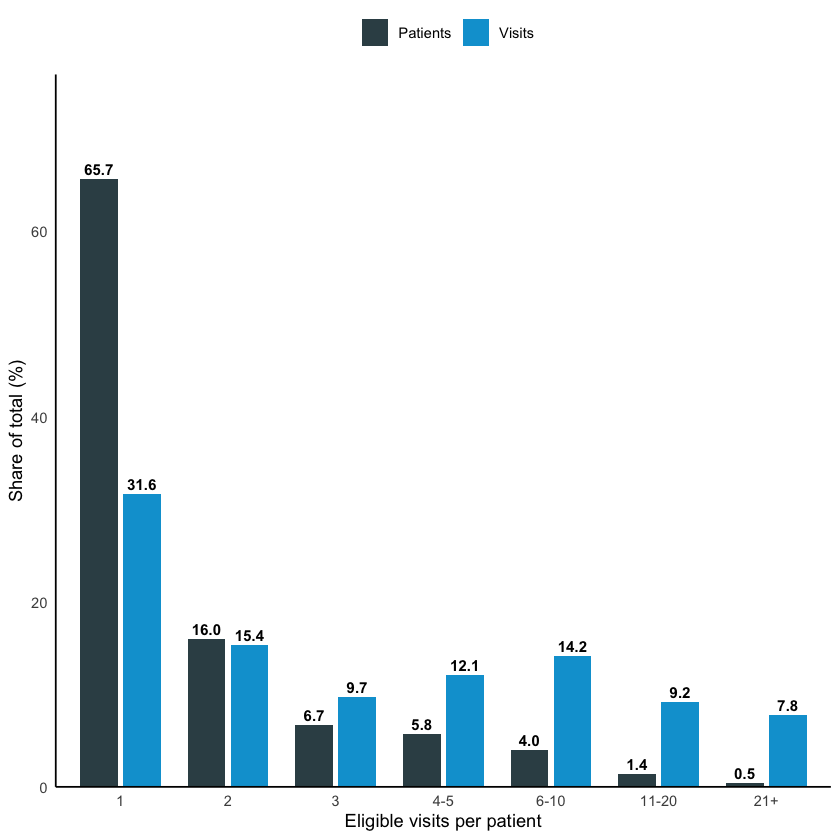

In [20]:
fig_1a_data <- vpp_bands |>
  select(band, Patients = pct_patients, Visits = pct_visits) |>
  pivot_longer(
    cols      = c(Patients, Visits),
    names_to  = "measure",
    values_to = "percent"
  )

figure_1a <- fig_1a_data |>
  ggplot(aes(x = band, y = percent, fill = measure)) +
  geom_col(position = position_dodge(width = 0.8), width = 0.7) +
  geom_text(
    aes(label = sprintf("%.1f", percent)),
    position = position_dodge(width = 0.8),
    vjust = -0.4, size = 3.2, fontface = "bold"
  ) +
  theme_minimal() +
  labs(
    x    = "Eligible visits per patient",
    y    = "Share of total (%)",
    fill = ""
  ) +
  scale_y_continuous(
    expand = expansion(mult = c(0, 0.1)),
    limits = c(0, 70)
  ) +
  scale_fill_manual(values = jama_palette[c(1, 3)]) +
  theme(
    panel.grid = element_blank(),
    legend.position = "top",
    axis.line = element_line(color = "black")
  )

figure_1a

## Figure 1B

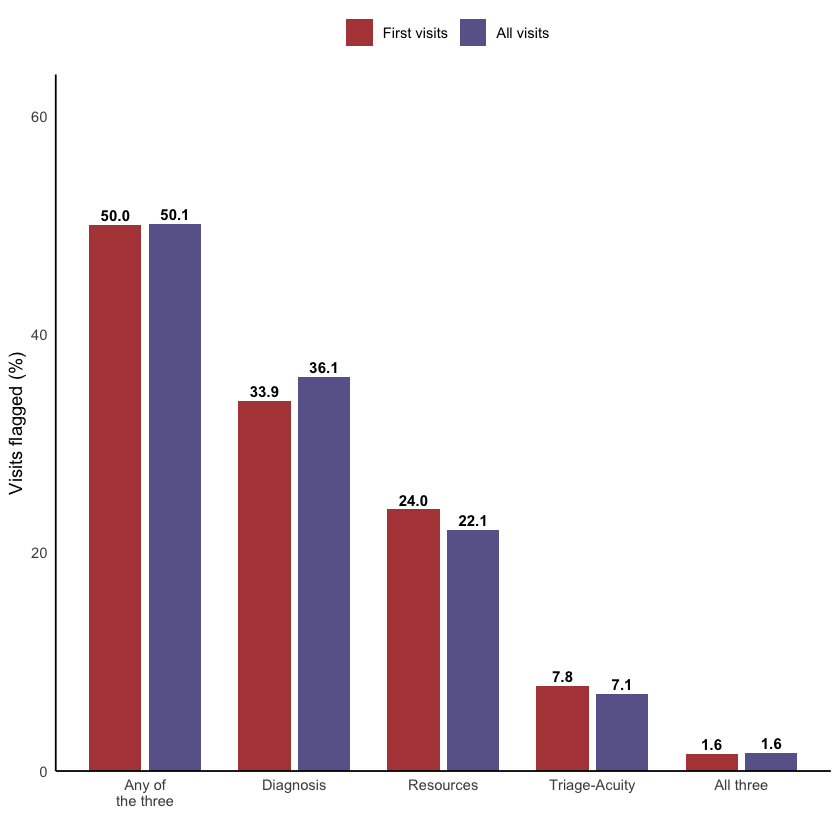

In [21]:
fig_1b_data <- totals_side |>
  select(algorithm, `First visits` = pct_first, `All visits` = pct_all) |>
  pivot_longer(
    cols      = c(`First visits`, `All visits`),
    names_to  = "sample",
    values_to = "percent"
  ) |>
  mutate(
    algorithm = factor(algorithm, levels = totals_order),
    sample    = factor(sample, levels = c("First visits", "All visits"))
  )

figure_1b <- fig_1b_data |>
  ggplot(aes(x = algorithm, y = percent, fill = sample)) +
  geom_col(position = position_dodge(width = 0.8), width = 0.7) +
  geom_text(
    aes(label = sprintf("%.1f", percent)),
    position = position_dodge(width = 0.8),
    vjust = -0.4, size = 3.2, fontface = "bold"
  ) +
  theme_minimal() +
  labs(
    x    = "",
    y    = "Visits flagged (%)",
    fill = ""
  ) +
  scale_x_discrete(
    labels = \(x) str_wrap(x, width = 9)
  ) +
  scale_y_continuous(
    expand = expansion(mult = c(0, 0.1)),
    limits = c(0, 58)
  ) +
  scale_fill_manual(values = jama_palette[c(4, 6)]) +
  theme(
    panel.grid = element_blank(),
    legend.position = "top",
    axis.line = element_line(color = "black")
  )

figure_1b

## Join

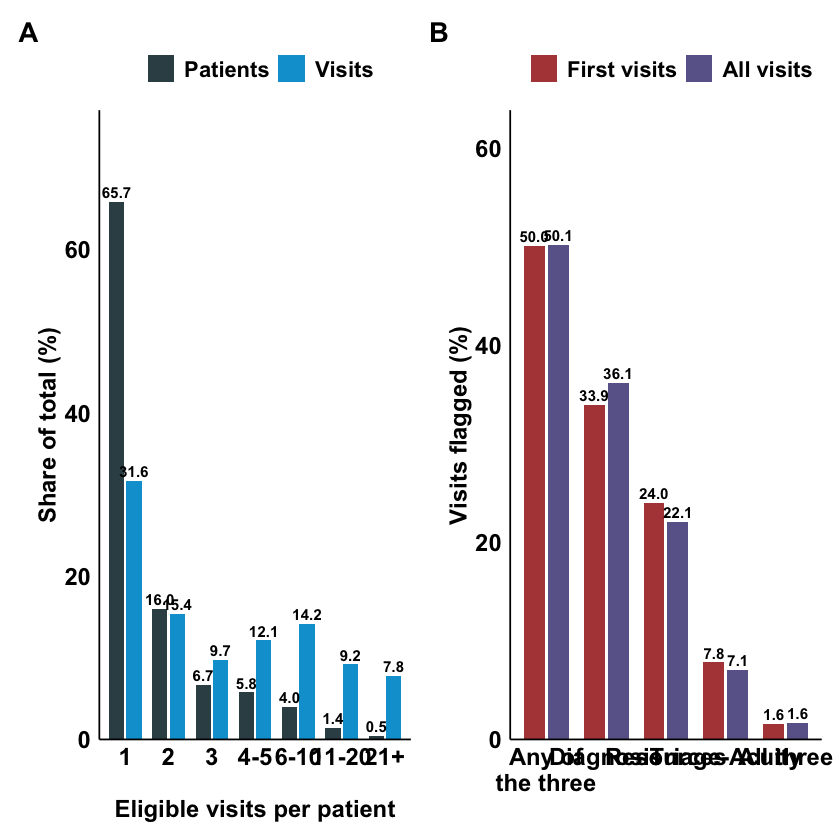

In [22]:
Figure_1 <- figure_1a + figure_1b +
  plot_annotation(
    tag_levels = "A"
  )&
  theme(
    plot.tag = element_text(
      color = "black",
      size = rel(1.5),
      face = "bold"
    ),
    axis.text = element_text(
      size = rel(1.3),
      colour = "black",
      face = "bold"
    ),
    axis.title = element_text(
      size = rel(1.3),
      colour = "black",
      face = "bold"
    ),
    legend.text = element_text(
      size = rel(1.2),
      colour = "black",
      face = "bold"
    )
  )

ggsave("s2_figure_1.png", plot = Figure_1, device = "png", width = 15, height = 7, units = "in", dpi = 600)
ggsave("s2_figure_1.svg", plot = Figure_1, device = "svg", width = 15, height = 7, units = "in")
ggsave("s2_figure_1.pdf", plot = Figure_1, device = "pdf", width = 15, height = 7, units = "in")
Figure_1


# What the all-visit column can and can't say

The all-visit numbers treat 417,723 visits as 417,723 independent observations, and they are not. The patient who attended 320 times contributes 320 rows, and their diagnoses, triage scores and resource use are correlated across their own visits. So the percentages and kappas in the all-visit column are weighted towards frequent attenders, and the confidence intervals are narrower than they should be - the effective sample size is much closer to 201,106 patients than to 417,723 visits. The point estimates are the right visit-level proportions; it is the precision that is overstated.

The two columns also answer different questions. First visits give the share of *patients* whose index visit is potentially avoidable; all visits give the share of *attendances*.

# Conclusions

The three headline findings hold in both versions.

About half of visits are flagged by at least one algorithm - 50.0% on first visits, 50.1% on all eligible visits. Agreement between the algorithms is poor either way, kappa 0.039 to 0.131 on first visits and 0.048 to 0.135 on all visits, slight agreement on every pairing. And about 1.6% are flagged by all three, 1.58% against 1.65%. No individual algorithm shifts by more than 2.2 percentage points.

So the first-visit restriction is best described as a choice of the patient rather than the visit as the unit of analysis, which keeps the observations independent. It does not drive the result.